# Superposed Epoch for all plasmoid events (separately for tailward and planetward)

In [1]:
import glob
import numpy as np
import pandas as pd
import datetime as dt

import matplotlib

import matplotlib.pyplot as plt 


from JunoPy.index import IndexFile
from JunoPy.mag import MagData
from JunoPy.library import find_ticks_between

In [2]:
def read_csv(filename):
    
    start_times = []
    end_times = []
    with open(filename, 'r') as f:
        
        f.readline()
        for line in f:
            linesplit = line.split(',')
            start_time = dt.datetime.strptime(linesplit[0].strip(), '%Y-%jT%H:%M:%S')
            end_time = dt.datetime.strptime(linesplit[1].strip(), '%Y-%jT%H:%M:%S')
            direction = linesplit[2]
            plasmoidtype = linesplit[3]
            
            yield start_time, end_time, direction, plasmoidtype

In [3]:
def identify_center_event(magdata):
    """
    Input: Shortened magdata with start and end as [0], [-1] indices.
    Given the start and end times for an event, identify the center using a linear fit. 
    """
    t1 = magdata.df.index[0]
    t2 = magdata.df.index[-1]
    Btheta1 = magdata.df.loc[t1, 'Btheta']
    Btheta2 = magdata.df.loc[t2, 'Btheta']
    
    
    return t1 - Btheta1 / (Btheta2 - Btheta1) * (t2 - t1)

In [4]:
def plot_all_data(magdata_list, center_list, dt=200, outfolder=None, direction='tailward'):
    
    # timearray, tickstring = find_ticks_between(start, end)
    
    
    # Create the figure.
    fig, axs = plt.subplots(4, 1, 
                            gridspec_kw={'hspace': 0.1, 'right':0.9, 'top':0.9}, 
                            figsize=(4.5, 5.5), 
                            dpi=150)
    
    df_concatenated = pd.DataFrame()
    for magdata, center in zip(magdata_list, center_list):
        
        
        magdata.df['TimeFromEpoch'] = (magdata.df.index - center).total_seconds()
        
        
        
        axs[0].plot(magdata.df['TimeFromEpoch'], magdata.df['Br'], color='0.8')
        axs[1].plot(magdata.df['TimeFromEpoch'], magdata.df['Btheta'], color='0.8')
        axs[2].plot(magdata.df['TimeFromEpoch'], magdata.df['Bphi'], color='0.8')
        axs[3].plot(magdata.df['TimeFromEpoch'], magdata.df['Bmag'], color='0.8')
    
    
    
    # Do the averaging for the superposed epoch -----
    df_list = [x.df.copy() for x in magdata_list]
    
    for i in range(len(df_list)):
        df_list[i]['TimeFromEpoch_int'] = np.round(df_list[i]['TimeFromEpoch'])
        df_list[i].set_index(['TimeFromEpoch_int'], inplace=True)
        df_list[i] = df_list[i][['Br', 'Btheta', 'Bphi', 'Bmag']]
    
    df_concat = pd.concat((df_list))
    df_concat = df_concat.groupby(level=0).mean()

    axs[0].plot(df_concat.index, df_concat['Br'], color='b')
    axs[1].plot(df_concat.index, df_concat['Btheta'], color='b')
    axs[2].plot(df_concat.index, df_concat['Bphi'], color='b')
    axs[3].plot(df_concat.index, df_concat['Bmag'], color='b')
    
    # -------------------------
    
    for a in axs:
        a.set_xlim([magdata.df['TimeFromEpoch'][0], magdata.df['TimeFromEpoch'][-1]])
        a.axvline(0, ls='dashed', color='k')
        a.axhline(0, ls='dotted', color='k', lw=1.0)
#         a.set_xticks(timearray)
#         a.set_xticklabels(tickstring)
        a.label_outer()

    axs[-1].set_xlabel('Time from $B_\\theta$ reversal (s)')
            
    annotations = ['a)', 'b)', 'c)', 'd)']
    ylabels = ['$B_r$ (nT)', '$B_\\theta$ (nT)', '$B_\\phi$ (nT)', '$|B|$ (nT)']
    
    for i, a in enumerate(axs):
        a.set_ylabel(ylabels[i])
        a.text(0.93, 0.8, annotations[i], transform=a.transAxes, weight='bold')
        
    a.tick_params(axis='x', width=2, rotation=0)
    # a.xaxis.label.set_visible(False)
    
    fig.suptitle('Superposed Epoch ({:s})'.format(direction), y=0.95)
    
    if outfolder:
        fig.savefig(outfolder + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
        plt.close(fig)
    
    plt.show()
    fig.savefig('out_images/superposed_epoch_{:s}.png'.format(direction), bbox_inches='tight')
    
    # plt.close(fig)


In [11]:
# def main(filename='auto_plasmoid_list_20210329_window10.csv'):
    

filename='auto_plasmoid_list_20210329_window10.csv'

center_planetward = []
center_tailward = []

magdata_planetward = []
magdata_tailward = []

for start, end, direction, plasmoidtype in read_csv(filename):
    
    # if 'o-line' in plasmoidtype:
    #    continue
        
    magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
    magdata = MagData(filename=magfile)
    magdata.df = magdata.df.loc[start:end]

    center = identify_center_event(magdata)

    magdata = MagData(filename=magfile)
    magdata.df = magdata.df.loc[center - dt.timedelta(minutes=2):
                                center + dt.timedelta(minutes=2)]
    
    if 'tailward' in direction:
        center_tailward.append(center)
        magdata_tailward.append(magdata)
    else:
        center_planetward.append(center)
        magdata_planetward.append(magdata)

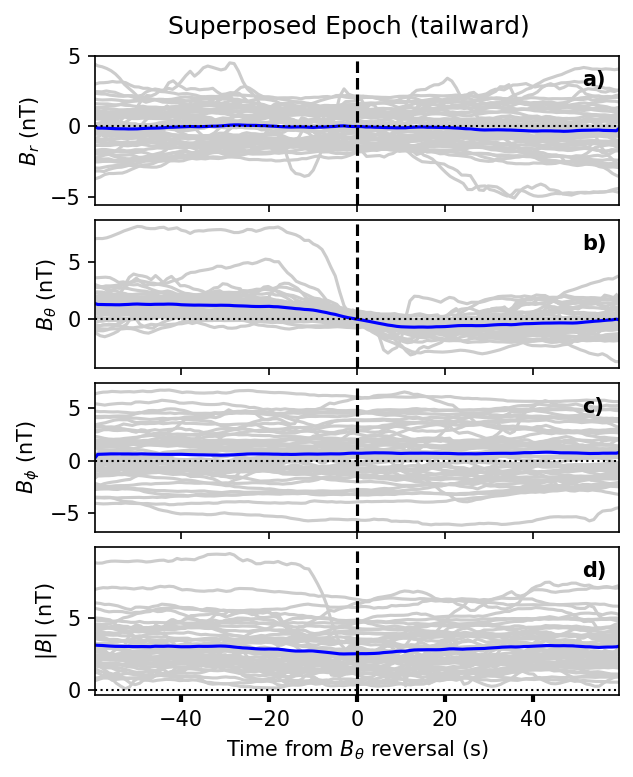

In [6]:

plot_all_data(magdata_tailward, center_tailward, direction='tailward')

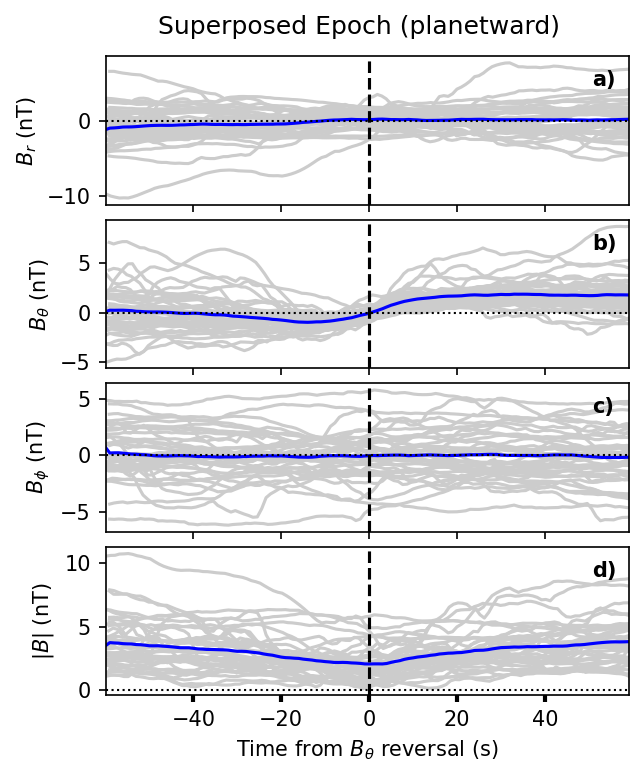

In [7]:
plot_all_data(magdata_planetward, center_planetward, direction='planetward')